In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import scipy.stats
import os
from matplotlib import rcParams
import sys
import tensorflow as tf
import multiprocessing

#tf.config.set_visible_devices([], 'GPU')  # Make all GPUs invisible

# Import GLM classes
sys.path.insert(0, '/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model')
import glm_class
from glm_class import make_prediction, deviance

# Set plotting style
rcParams['font.family'] = 'Arial'
rcParams['axes.spines.right'] = False
rcParams['axes.spines.top'] = False

print("✓ Imports complete")

✓ Imports complete


In [2]:
import pickle

load_path = '/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model/simulated_data/simulated_glm_data.pkl'
print(f"Loading data from: {load_path}")

with open(load_path, 'rb') as f:
    glm_data = pickle.load(f)

# Extract components
X = glm_data['X']  # Already z-scored
Y = glm_data['Y']  # Already scaled by 10 for deconv
metadata = glm_data['metadata']
predictor_names = glm_data['predictor_names']
predictor_info = glm_data['predictor_info'].copy()  # Make a copy to modify
group_indices      = glm_data['group_indices']
synthetic_glm_dict = glm_data.get('synthetic_glm_dict', {})
ground_truth       = glm_data.get('ground_truth', {})

print(f"\n✓ Data loaded successfully!")
print(f"  X shape: {X.shape} (frames × predictors)")
print(f"  Y shape: {Y.shape} (frames × neurons)")

# Check if constant predictor exists and remove it (for old data files)
if 'constant' in predictor_info:
    # Check if X already cleaned
    expected_features_with_constant = sum(info['end'] - info['start'] for info in predictor_info.values())
    
    if X.shape[1] == expected_features_with_constant:
        # X still has constant, remove it from X
        print("\n⚠️  Detected old data format with 'constant' predictor - removing from X...")
        
        const_start = predictor_info['constant']['start']
        const_end = predictor_info['constant']['end']
        
        # Remove constant column from X
        keep_mask = np.ones(X.shape[1], dtype=bool)
        keep_mask[const_start:const_end] = False
        X = X[:, keep_mask]
        
        # Update predictor_names
        predictor_names = [predictor_names[i] for i in range(len(predictor_names)) if keep_mask[i]]
        
        print(f"  ✓ Removed constant predictor from X")
        print(f"  New X shape: {X.shape}")
    else:
        # X already cleaned, just note it
        print("\n⚠️  X already cleaned but metadata still has 'constant' entry")
    
    # Always clean predictor_info if 'constant' exists
    print("  Cleaning predictor_info metadata...")
    const_start = predictor_info['constant']['start']
    const_end = predictor_info['constant']['end']
    offset = const_end - const_start
    
    predictor_info_clean = {}
    for group_name, info in predictor_info.items():
        if group_name == 'constant':
            continue
        predictor_info_clean[group_name] = {
            'start': info['start'] if info['start'] < const_start else info['start'] - offset,
            'end': info['end'] if info['end'] <= const_start else info['end'] - offset,
            'names': info['names']
        }
    predictor_info = predictor_info_clean
    print(f"  ✓ Cleaned predictor_info")
else:
    print("\n✓ Data already clean (no constant predictor)")

print(f"\nFinal data shapes:")
print(f"  X: {X.shape}")
print(f"  Y: {Y.shape}")
print(f"  Predictor groups: {list(predictor_info.keys())}")

Loading data from: /Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model/simulated_data/simulated_glm_data.pkl

✓ Data loaded successfully!
  X shape: (40224, 146) (frames × predictors)
  Y shape: (40224, 22) (frames × neurons)

✓ Data already clean (no constant predictor)

Final data shapes:
  X: (40224, 146)
  Y: (40224, 22)
  Predictor groups: ['position_only', 'sound', 'visual', 'velocity', 'choice_spatial', 'turn_onset', 'reward_hit', 'reward_miss']


In [3]:
print("Data Verification")
print("="*60)

# Check X (design matrix)
print("\nX (Design Matrix):")
print(f"  Mean: {np.mean(X):.6f} (should be ≈0)")
print(f"  Std:  {np.std(X):.3f} (should be ≈1)")
print(f"  Range: [{np.min(X):.2f}, {np.max(X):.2f}]")
print(f"  NaN count: {np.sum(np.isnan(X))}")
print(f"  Inf count: {np.sum(np.isinf(X))}")

# Check Y (neural data)
print("\nY (Neural Data):")
print(f"  Mean: {np.mean(Y):.3f}")
print(f"  Std:  {np.std(Y):.3f}")
print(f"  Range: [{np.min(Y):.2f}, {np.max(Y):.2f}]")
print(f"  NaN count: {np.sum(np.isnan(Y))}")
print(f"  Inf count: {np.sum(np.isinf(Y))}")

# Check metadata
print("\nMetadata (Context distribution):")
for ctx in [0, 1, 2]:
    n_frames = np.sum(metadata['context'] == ctx)
    pct = n_frames / len(metadata['context']) * 100
    print(f"  Context {ctx}: {n_frames:,} frames ({pct:.1f}%)")

print("\n✓ Data verification complete")

Data Verification

X (Design Matrix):
  Mean: 0.000000 (should be ≈0)
  Std:  0.976 (should be ≈1)
  Range: [-1.33, 24.66]
  NaN count: 0
  Inf count: 0

Y (Neural Data):
  Mean: 9.407
  Std:  7.910
  Range: [0.00, 289.00]
  NaN count: 0
  Inf count: 0

Metadata (Context distribution):
  Context 0: 13,182 frames (32.8%)
  Context 1: 13,418 frames (33.4%)
  Context 2: 13,624 frames (33.9%)

✓ Data verification complete


In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------------
# Build balanced trial set across contexts and choices, then 70/30 split
# ------------------------------------------------------------------

# Assumes metadata has per-frame entries:
#   - 'trial_id'
#   - 'context'  (0,1,2)
#   - 'choice'   (e.g. 0 = Left, 1 = Right)

# Make a per-trial summary table
trial_df = (
    pd.DataFrame({
        'trial_id': metadata['trial_id'],
        'context': metadata['context'],
        'choice':  metadata['choice'],
    })
    .drop_duplicates(subset='trial_id')
)

# Collect balanced trial_ids: equal # of L/R per context
balanced_trial_ids = []

rng = np.random.default_rng(seed=0)  # for reproducibility

for ctx in [0, 1, 2]:
    trials_ctx = trial_df[trial_df['context'] == ctx]

    left_trials  = trials_ctx[trials_ctx['choice'] == 0]['trial_id'].to_numpy()
    right_trials = trials_ctx[trials_ctx['choice'] == 1]['trial_id'].to_numpy()

    if len(left_trials) == 0 or len(right_trials) == 0:
        print(f"Warning: context {ctx} missing one choice side; skipping balancing for that side.")
        n_bal = min(len(left_trials), len(right_trials))
    else:
        n_bal = min(len(left_trials), len(right_trials))

    if n_bal == 0:
        continue  # no usable trials in this context

    left_sel  = rng.choice(left_trials,  size=n_bal, replace=False)
    right_sel = rng.choice(right_trials, size=n_bal, replace=False)

    balanced_trial_ids.extend(left_sel.tolist())
    balanced_trial_ids.extend(right_sel.tolist())

balanced_trial_ids = np.array(balanced_trial_ids)
print(f"Using {len(balanced_trial_ids)} balanced trials total.")

# Create a per-trial table for the balanced set
balanced_trials_df = trial_df[trial_df['trial_id'].isin(balanced_trial_ids)].copy()

# For stratification, encode (context, choice) as a single label
strat_labels = balanced_trials_df['context'] * 10 + balanced_trials_df['choice']

# 70/30 split at the TRIAL level
train_trials, test_trials = train_test_split(
    balanced_trials_df['trial_id'].to_numpy(),
    test_size=0.3,
    random_state=0,
    shuffle=True,
    stratify=strat_labels
)

train_trials = np.array(train_trials)
test_trials  = np.array(test_trials)

# ------------------------------------------------------------------
# Convert trial-level split back to frame-level masks
# ------------------------------------------------------------------
train_mask = np.isin(metadata['trial_id'], train_trials)
test_mask  = np.isin(metadata['trial_id'], test_trials)

# Apply to X / Y / metadata
X_train = X[train_mask]
Y_train = Y[train_mask]
trial_id_train = metadata['trial_id'][train_mask]

X_test = X[test_mask]
Y_test = Y[test_mask]
trial_id_test = metadata['trial_id'][test_mask]

# ------------------------------------------------------------------
# Diagnostics
# ------------------------------------------------------------------
print("Train/Test Split on balanced trials (contexts 0,1,2; balanced L/R within each context)")
print("=" * 60)
print(f"\nTraining Set:")
print(f"  Frames: {X_train.shape[0]:,} ({X_train.shape[0]/X.shape[0]*100:.1f}%)")
print(f"  Trials: {len(np.unique(trial_id_train))}")

print(f"\nTest Set:")
print(f"  Frames: {X_test.shape[0]:,} ({X_test.shape[0]/X.shape[0]*100:.1f}%)")
print(f"  Trials: {len(np.unique(trial_id_test))}")

print("\nTraining Set Balance (by context × choice):")
for ctx in [0, 1, 2]:
    for ch, ch_name in [(0, 'L'), (1, 'R')]:
        mask = (metadata['context'] == ctx) & (metadata['choice'] == ch) & train_mask
        n_frames = np.sum(mask)
        if n_frames > 0:
            pct = n_frames / X_train.shape[0] * 100
            print(f"  Context {ctx}, {ch_name}: {n_frames:,} frames ({pct:.1f}%)")

print("\n✓ Balanced trial selection and 70/30 split complete")

Using 300 balanced trials total.
Train/Test Split on balanced trials (contexts 0,1,2; balanced L/R within each context)

Training Set:
  Frames: 28,099 (69.9%)
  Trials: 210

Test Set:
  Frames: 12,125 (30.1%)
  Trials: 90

Training Set Balance (by context × choice):
  Context 0, L: 4,690 frames (16.7%)
  Context 0, R: 4,615 frames (16.4%)
  Context 1, L: 4,694 frames (16.7%)
  Context 1, R: 4,607 frames (16.4%)
  Context 2, L: 4,760 frames (16.9%)
  Context 2, R: 4,733 frames (16.8%)

✓ Balanced trial selection and 70/30 split complete


In [5]:
def get_feature_group_size(predictor_info):
    """
    Convert predictor_info to feature_group_size for GLM_CV.
    
    predictor_info: dict with 'start', 'end' for each group
    Returns: array of group sizes
    """
    group_sizes = []
    for group_name, info in predictor_info.items():
        group_sizes.append(info['end'] - info['start'])
    return np.array(group_sizes)

feature_group_size = get_feature_group_size(predictor_info)

print("Feature Groups for Group Lasso:")
print("="*60)
for i, (group_name, group_data) in enumerate(predictor_info.items()):
    print(f"{group_name:20s}: {feature_group_size[i]:2d} features")
print(f"\nTotal: {np.sum(feature_group_size)} features")
print(f"X_train has: {X_train.shape[1]} features")

# Verify they match
if np.sum(feature_group_size) == X_train.shape[1]:
    print("\n✓ Feature groups match X dimensions!")
else:
    print(f"\n❌ MISMATCH: {np.sum(feature_group_size)} group features != {X_train.shape[1]} X features")

Feature Groups for Group Lasso:
position_only       : 10 features
sound               : 20 features
visual              : 20 features
velocity            : 20 features
choice_spatial      : 60 features
turn_onset          :  8 features
reward_hit          :  4 features
reward_miss         :  4 features

Total: 146 features
X_train has: 146 features

✓ Feature groups match X dimensions!


In [6]:

print("System Resources:")
print("="*60)
print(f"TensorFlow version: {tf.__version__}")

# Check for Metal GPU on Mac
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"\n✓ GPU Available: {len(gpus)} device(s)")
    for gpu in gpus:
        print(f"  - {gpu}")
    
    # Enable memory growth
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("  ✓ Memory growth enabled")
    except:
        pass
else:
    print("\n⚠️  No GPU detected")

# CPU info
n_cores = multiprocessing.cpu_count()
print(f"\nCPU cores: {n_cores}")
print("="*60)

System Resources:
TensorFlow version: 2.16.2

✓ GPU Available: 1 device(s)
  - PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
  ✓ Memory growth enabled

CPU cores: 24


In [7]:
# Clear any previous keras states
tf.keras.backend.clear_session()

# Initialize GLM_CV (following Harvey Lab tutorial)
model_cv = glm_class.GLM_CV(
    n_folds=3,
    auto_split=True,
    split_by_group=True,
    activation='exp', #'exp', 'softplus'
    loss_type='poisson', #'poisson', 'gaussian'
    regularization='group_lasso',
    lambda_series=10.0 ** np.linspace(-1, -6, 11),
    l1_ratio=0.95,
    smooth_strength=0.1,
    optimizer='adam',
    learning_rate=1e-2,
    convergence_tol=1e-6
)

print("Model Configuration:")
print("="*60)
print(f"  Activation: {model_cv.activation}")
print(f"  Loss: {model_cv.loss_type}")
print(f"  Regularization: {model_cv.regularization}")
print(f"  Lambda range: [{model_cv.lambda_series.min():.2e}, {model_cv.lambda_series.max():.2e}]")
print(f"  N lambdas: {len(model_cv.lambda_series)}")
print(f"  CV folds: {model_cv.n_folds}")
print(f"  Learning rate: {model_cv.learning_rate}")
print("="*60)
print("\n✓ Model initialized")

Model Configuration:
  Activation: exp
  Loss: poisson
  Regularization: group_lasso
  Lambda range: [1.00e-06, 1.00e-01]
  N lambdas: 11
  CV folds: 3
  Learning rate: 0.01

✓ Model initialized


In [8]:
print("Fitting GLM with 3-fold cross-validation...\n")
print(f"Training on {Y_train.shape[1]} neurons")
print(f"Training frames: {X_train.shape[0]:,}")
print(f"Predictors: {X_train.shape[1]}")
print("="*60)

# Fit the model
model_cv.fit(
    X_train,
    Y_train,
    group_idx=trial_id_train,
    feature_group_size=feature_group_size,
    verbose=True
)

print("\n✓ Model fitting complete!")

Fitting GLM with 3-fold cross-validation...

Training on 22 neurons
Training frames: 28,099
Predictors: 146


2026-03-06 08:28:48.487737: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Ultra
2026-03-06 08:28:48.487781: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 128.00 GB
2026-03-06 08:28:48.487786: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 53.76 GB
2026-03-06 08:28:48.487999: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-03-06 08:28:48.488014: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


n_fold = 0
Lambda 0 iter 100 loss: -9.08754444 diff: 0.10189395
Lambda 0 iter 200 loss: -12.44861603 diff: 0.03346526
Lambda 0 iter 300 loss: -13.21322918 diff: 0.00754327
Lambda 0 iter 400 loss: -13.25948429 diff: 0.00045222
Lambda 0 iter 500 loss: -13.26086426 diff: 0.00001251
Fitting with Lambda 0 iter 600 converged (loss diff = -0.00000223)
Lambda 1 iter 100 loss: -13.39671707 diff: 0.00008767
Fitting with Lambda 1 iter 200 converged (loss diff = -0.00000039)
Lambda 2 iter 100 loss: -13.44356346 diff: 0.00001898
Fitting with Lambda 2 iter 200 converged (loss diff = 0.00000001)
Lambda 3 iter 100 loss: -13.45981312 diff: 0.00000608
Fitting with Lambda 3 iter 200 converged (loss diff = -0.00000005)
Fitting with Lambda 4 iter 100 converged (loss diff = 0.00000219)
Fitting with Lambda 5 iter 100 converged (loss diff = 0.00000041)
Fitting with Lambda 6 iter 100 converged (loss diff = -0.00000059)
Fitting with Lambda 7 iter 100 converged (loss diff = 0.00000097)
Fitting with Lambda 8 iter


Model Selection Results:
Mean CV frac_dev: 0.603
Median CV frac_dev: 0.659
Range: [0.172, 0.859]

Selected lambda range: [3.16e-03, 1.00e-01]
Median selected lambda: 3.16e-02

Neurons with frac_dev > 0.05: 22/22 (100.0%)


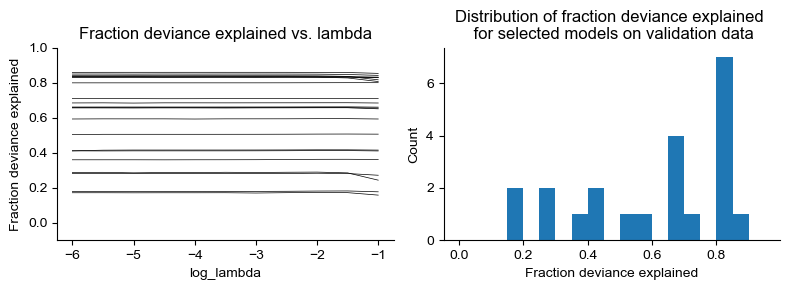

In [9]:
# Select best model for each neuron
model_cv.select_model(make_fig=True)

print("\nModel Selection Results:")
print("="*60)
print(f"Mean CV frac_dev: {np.mean(model_cv.selected_frac_dev_expl_cv):.3f}")
print(f"Median CV frac_dev: {np.median(model_cv.selected_frac_dev_expl_cv):.3f}")
print(f"Range: [{np.min(model_cv.selected_frac_dev_expl_cv):.3f}, {np.max(model_cv.selected_frac_dev_expl_cv):.3f}]")

print(f"\nSelected lambda range: [{model_cv.selected_lambda.min():.2e}, {model_cv.selected_lambda.max():.2e}]")
print(f"Median selected lambda: {np.median(model_cv.selected_lambda):.2e}")

# Count well-modeled neurons
good_neurons = np.sum(model_cv.selected_frac_dev_expl_cv > 0.05)
print(f"\nNeurons with frac_dev > 0.05: {good_neurons}/{Y_train.shape[1]} ({good_neurons/Y_train.shape[1]*100:.1f}%)")
print("="*60)

In [10]:
# Make predictions on test set
Y_test_pred = make_prediction(
    X_test,
    model_cv.selected_w,
    model_cv.selected_w0.flatten(),
    activation=model_cv.activation
)

# Calculate deviance explained on test set
# Note: deviance() expects 2D arrays and computes its own null model
# Just pass the full arrays at once!
test_frac_dev, test_d_model, test_d_null = deviance(
    Y_test_pred,  # predictions (n_samples, n_neurons)
    Y_test,       # true values (n_samples, n_neurons)
    loss_type=model_cv.loss_type
)

print("Test Set Performance (Context 0):")
print("="*60)
print(f"Mean frac_dev: {np.mean(test_frac_dev):.3f}")
print(f"Median frac_dev: {np.median(test_frac_dev):.3f}")
print(f"Range: [{np.min(test_frac_dev):.3f}, {np.max(test_frac_dev):.3f}]")

good_test = np.sum(test_frac_dev > 0.1)
print(f"\nNeurons with frac_dev > 0.1: {good_test}/{Y_test.shape[1]} ({good_test/Y_test.shape[1]*100:.1f}%)")
print("="*60)

Test Set Performance (Context 0):
Mean frac_dev: 0.596
Median frac_dev: 0.663
Range: [0.171, 0.861]

Neurons with frac_dev > 0.1: 22/22 (100.0%)


In [11]:
# Prepare results dictionary
results = {
    # Model weights and parameters
    'weights': model_cv.selected_w,
    'selected_lambda': model_cv.selected_lambda,
    
    # Performance metrics
    'cv_frac_dev': model_cv.selected_frac_dev_expl_cv,
    'test_frac_dev': test_frac_dev,
    
    # Metadata
    'predictor_names': predictor_names,
    'predictor_info': predictor_info,
    'feature_group_size': feature_group_size,
    
    # Model configuration
    'model_config': {
        'activation': model_cv.activation,
        'loss_type': model_cv.loss_type,
        'regularization': model_cv.regularization,
        'lambda_series': model_cv.lambda_series,
        'n_folds': model_cv.n_folds,
        'learning_rate': model_cv.learning_rate,
    },
    
    # Dataset info
    'mouse_ID': 'Simulated',
    'date': '2026-03-05',
    'train_contexts': [0, 1, 2],
    'test_context': [0, 1, 2],
}

# Save results
save_dir = '/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model/simulated_data/'
save_path = os.path.join(save_dir, 'glm_results_train_contexts_0_1_2_test_context_0_1_2.pkl')

with open(save_path, 'wb') as f:
    pickle.dump(results, f)

print(f"Results saved to: {save_path}")
print(f"File size: {os.path.getsize(save_path) / 1e6:.2f} MB")
print("\n✓ Save complete")

Results saved to: /Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model/simulated_data/glm_results_train_contexts_0_1_2_test_context_0_1_2.pkl
File size: 0.02 MB

✓ Save complete


Plotting 22 simulated neurons...



/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


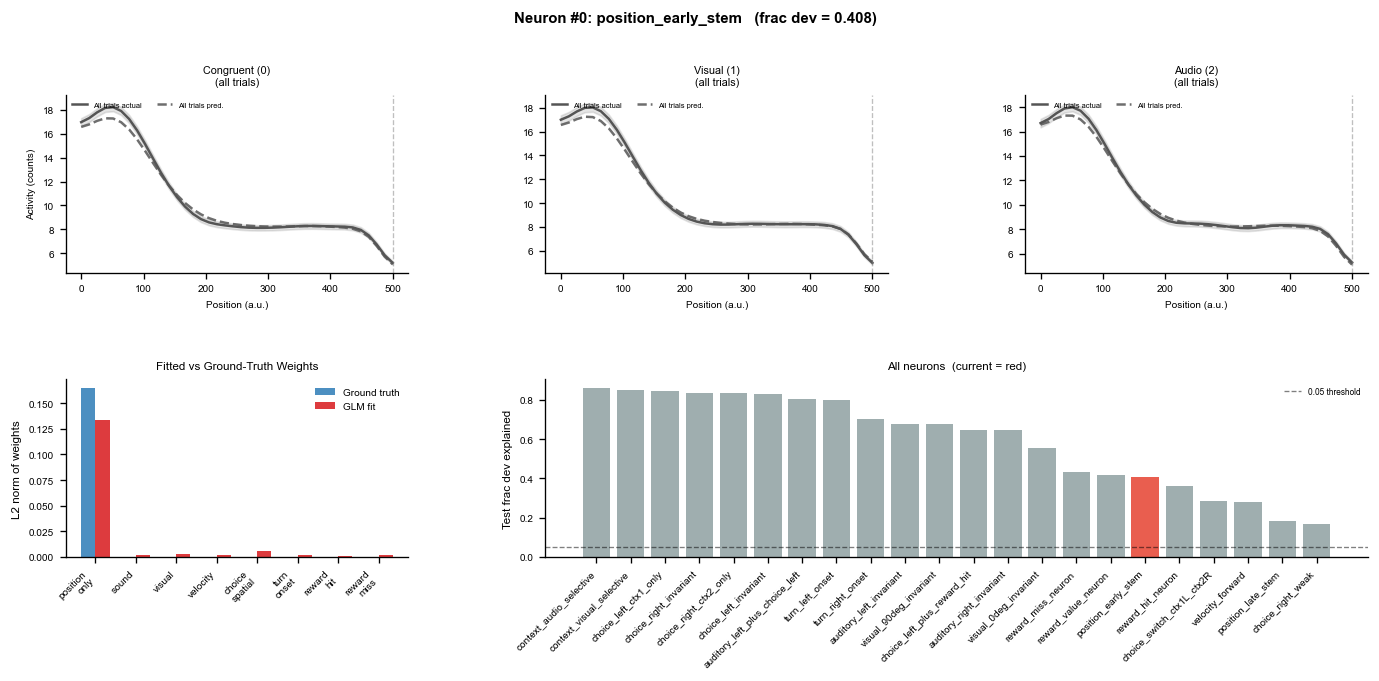

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


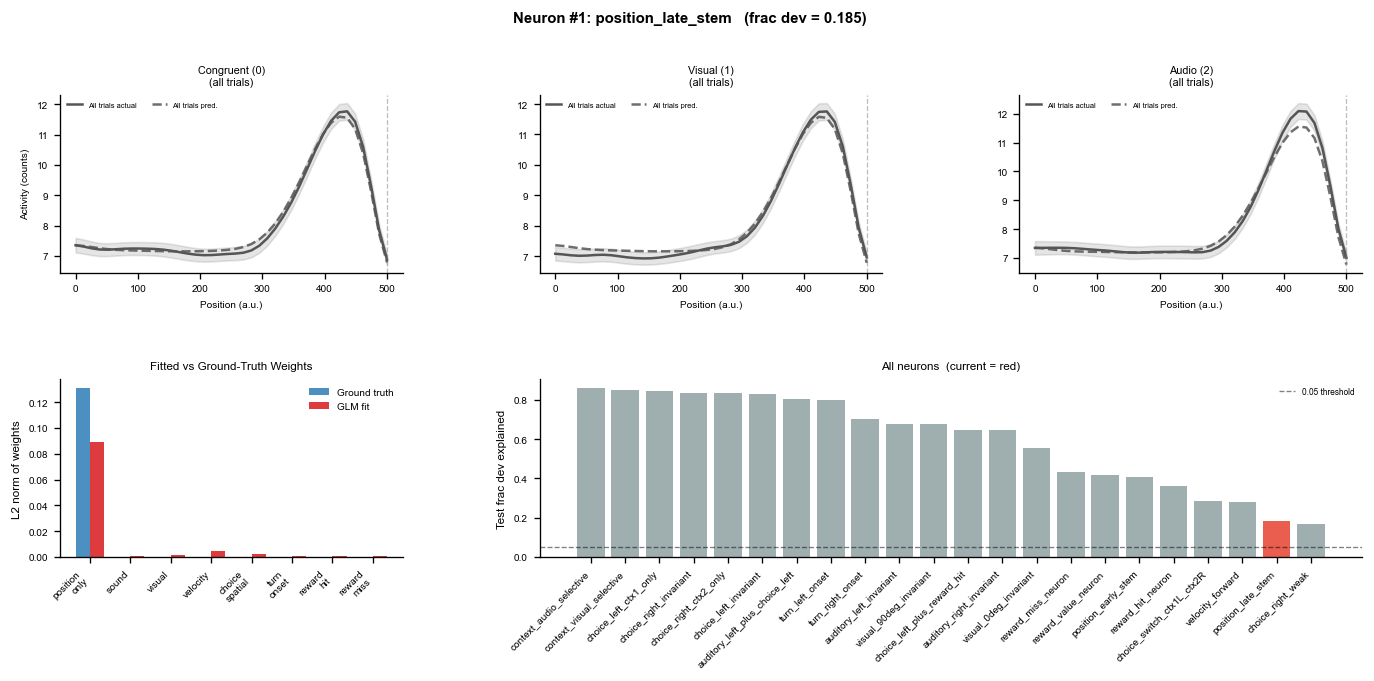

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


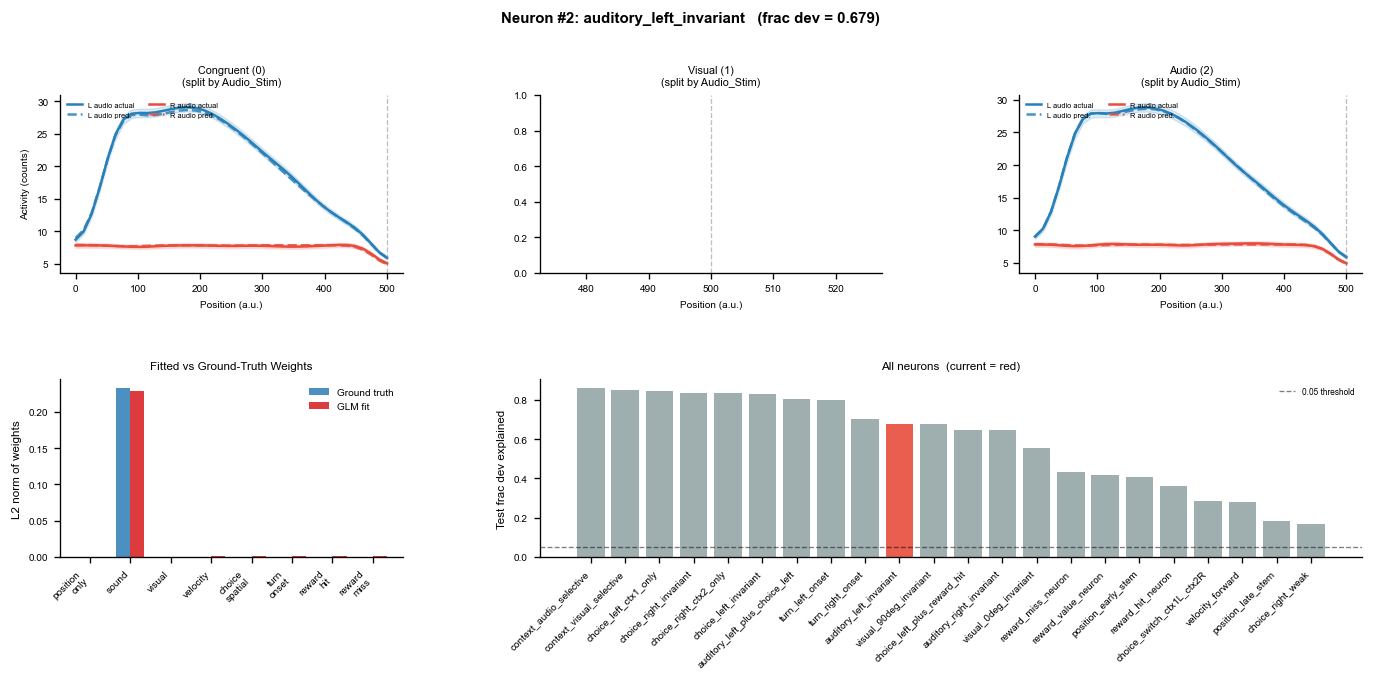

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


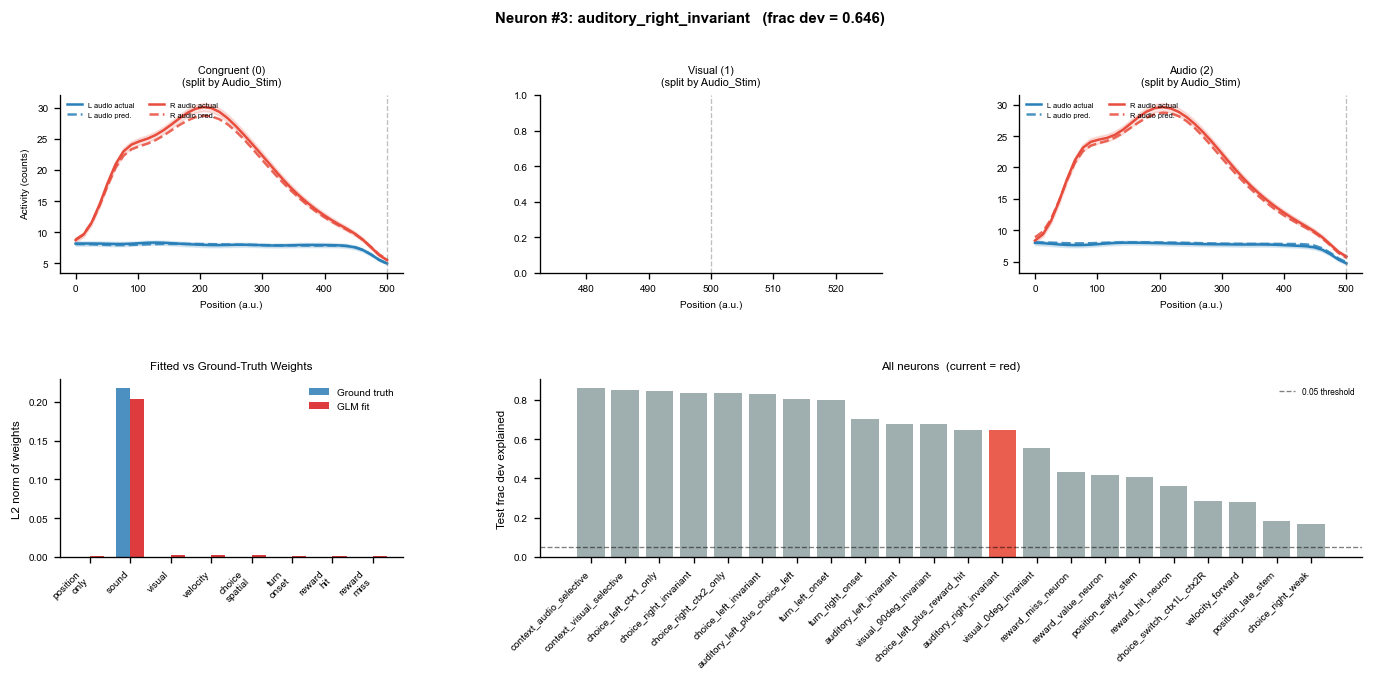

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


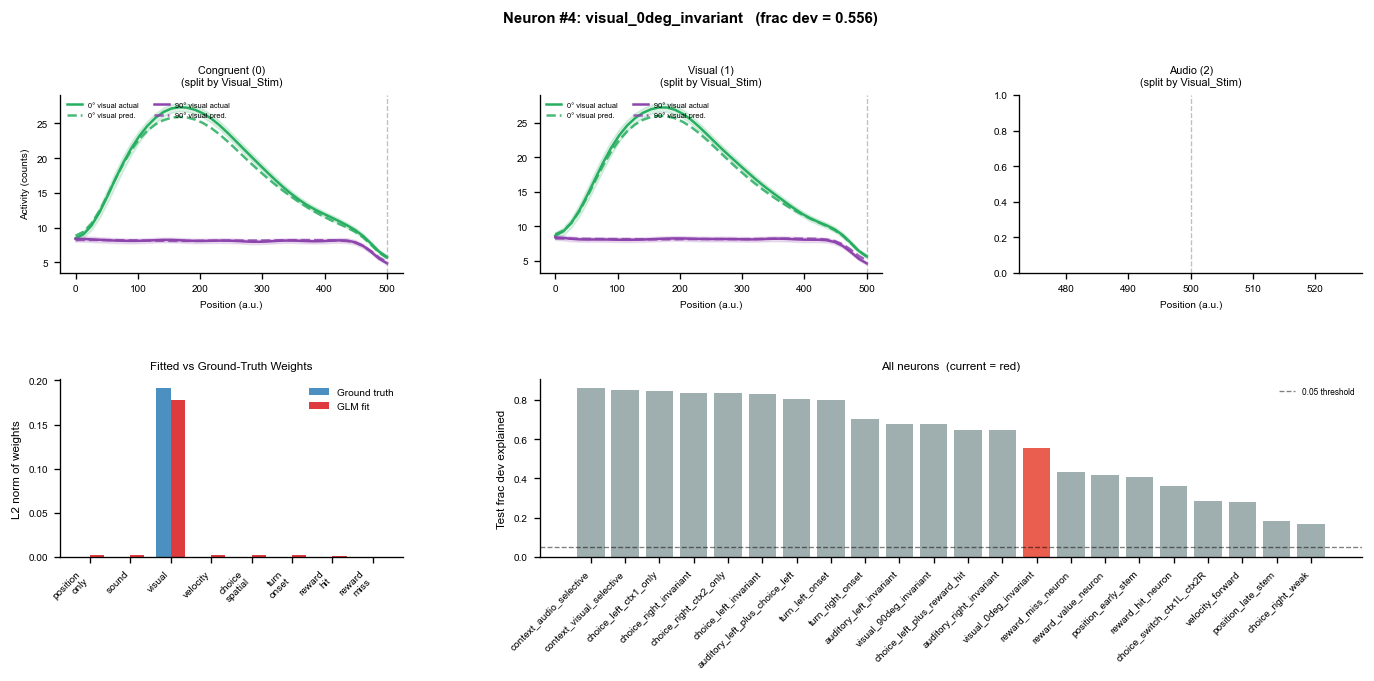

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


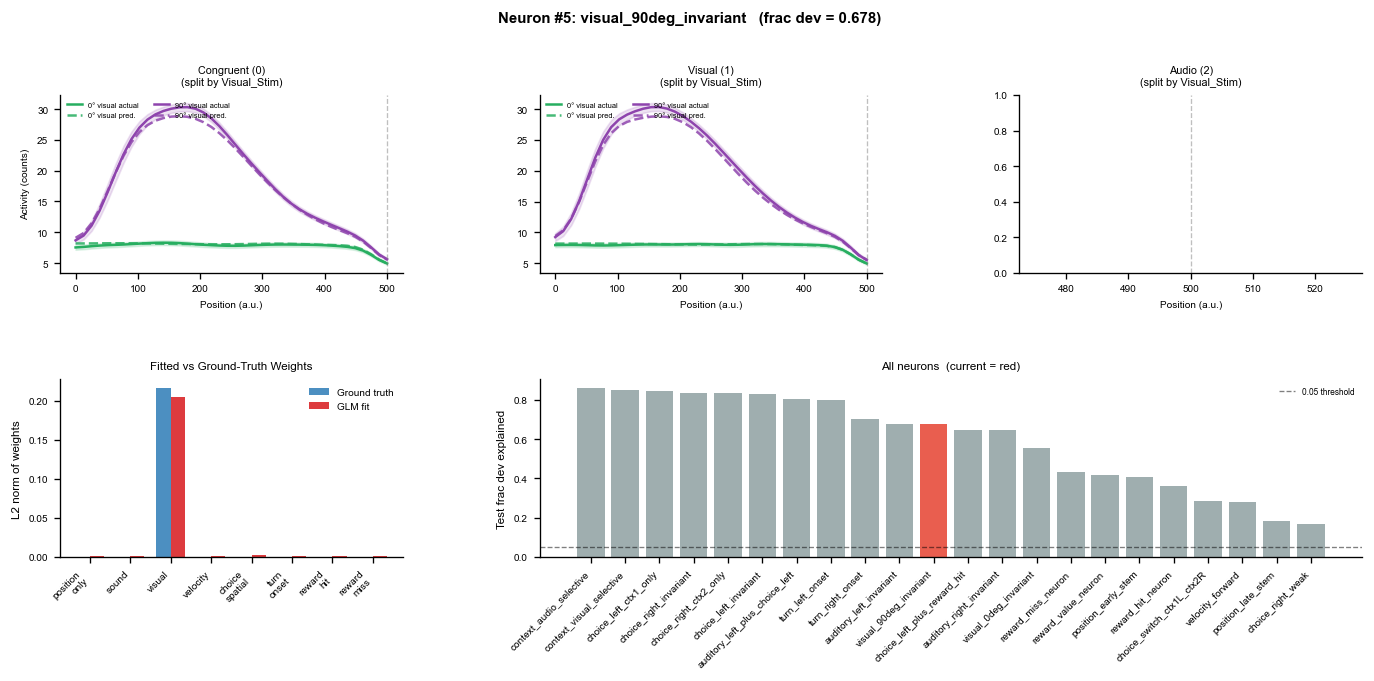

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


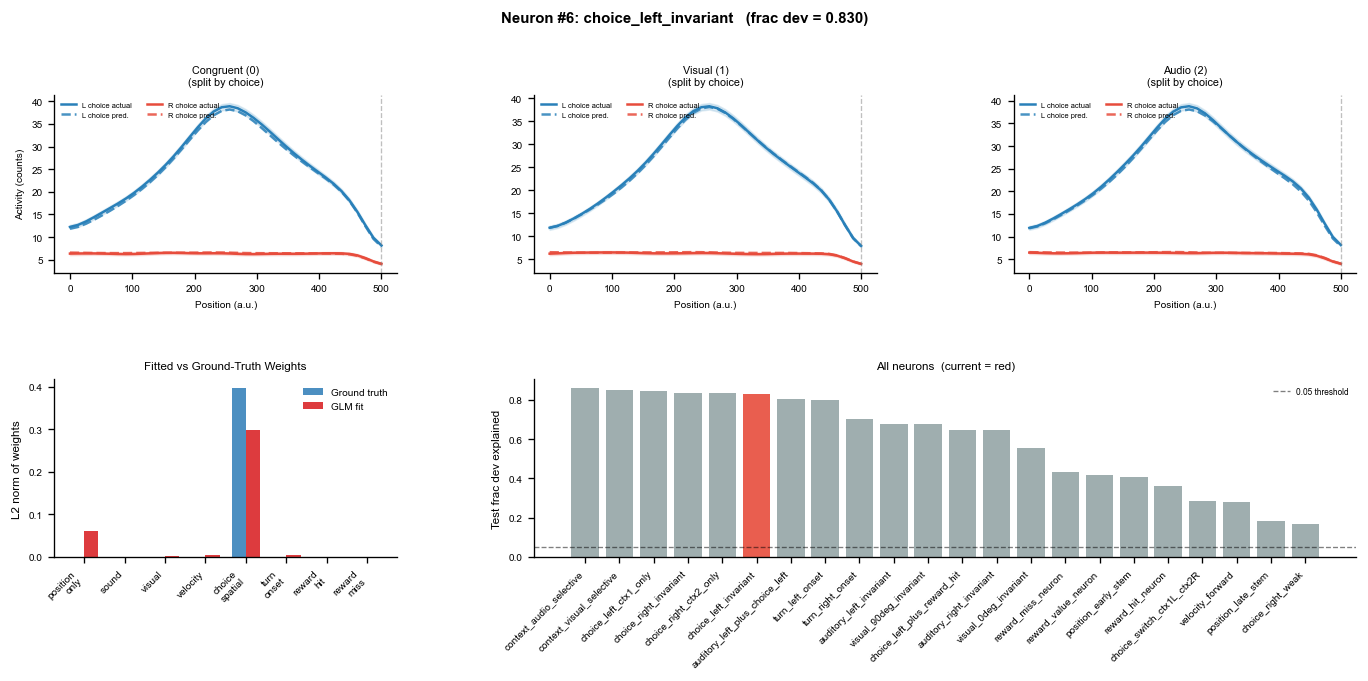

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


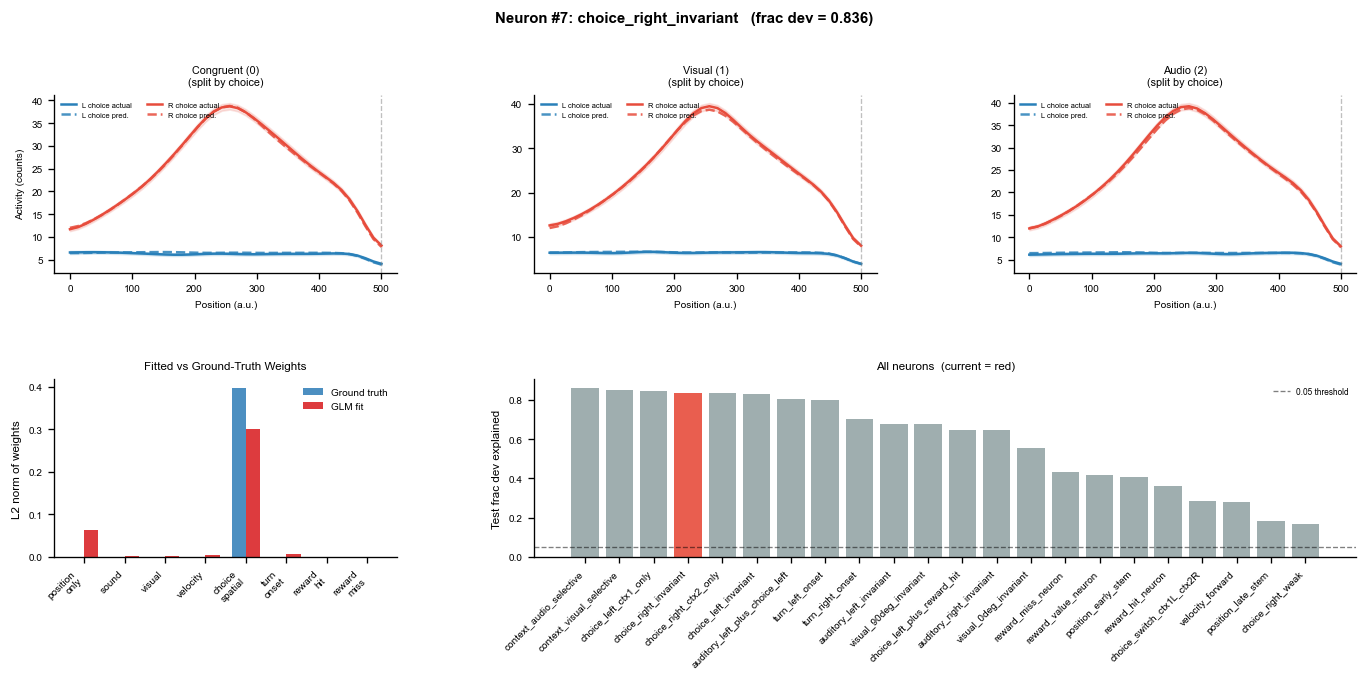

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


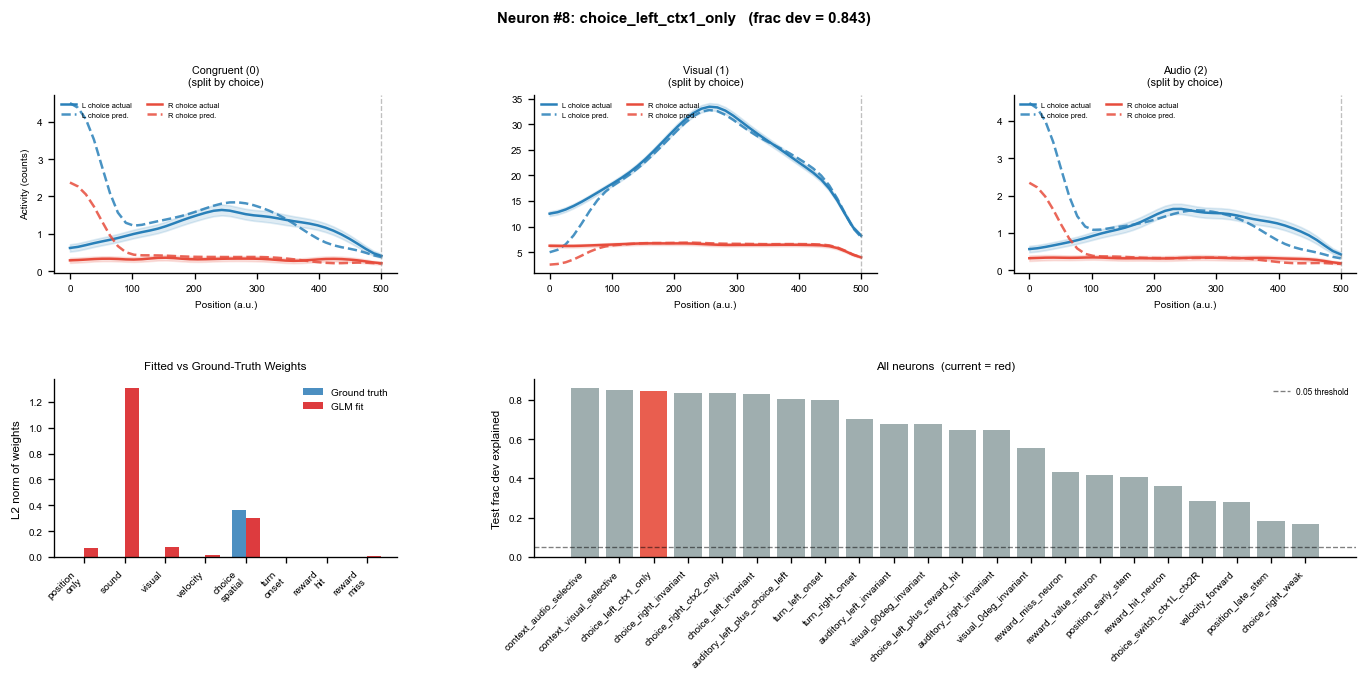

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


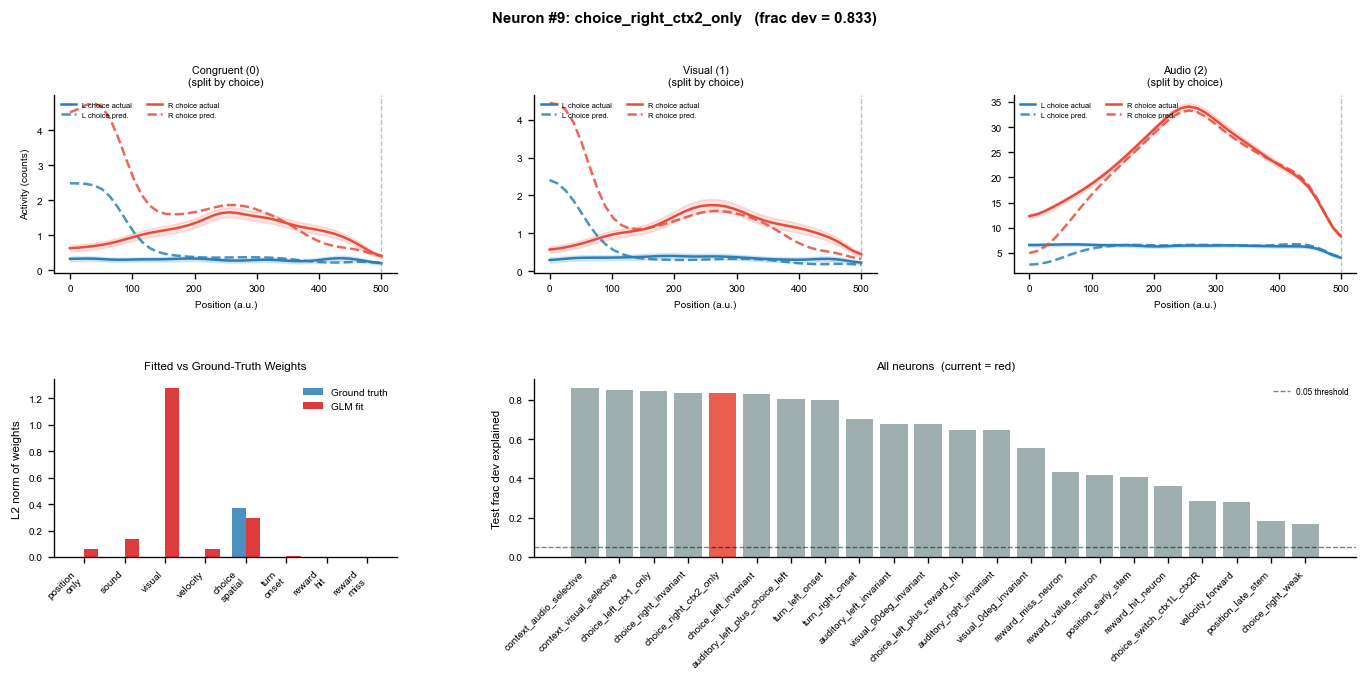

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


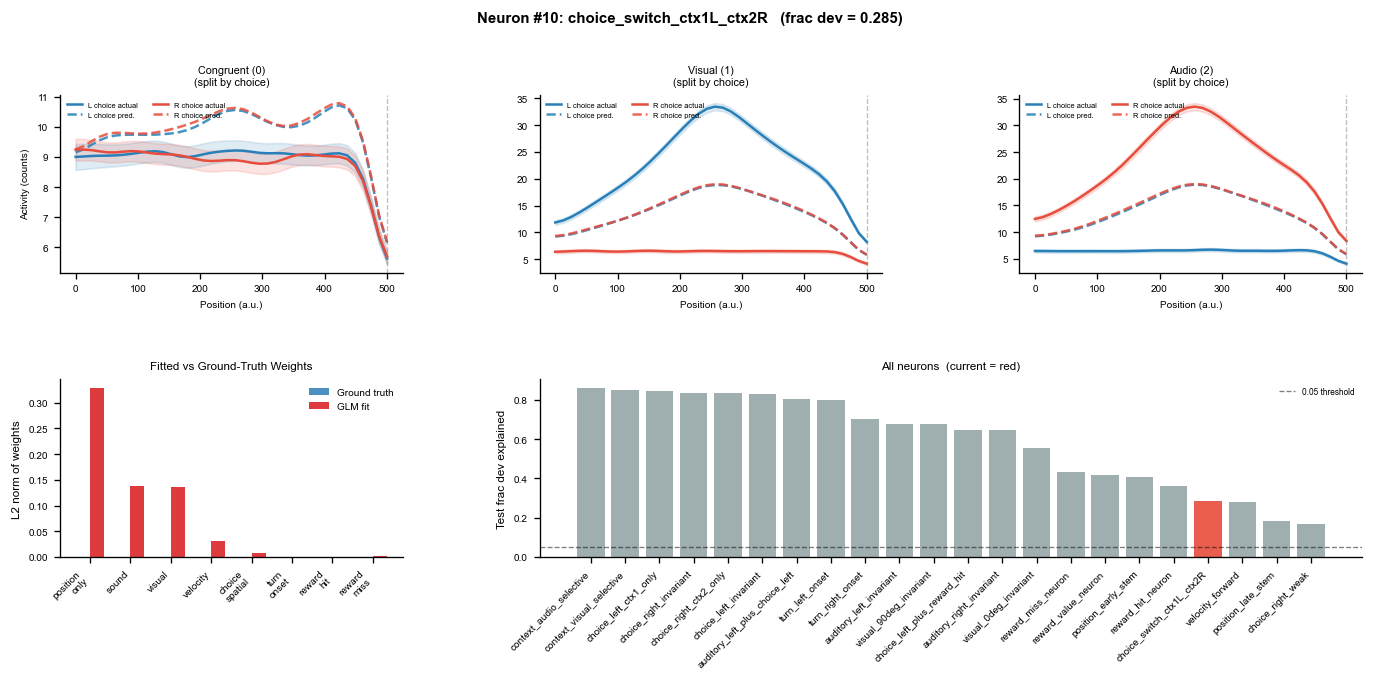

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


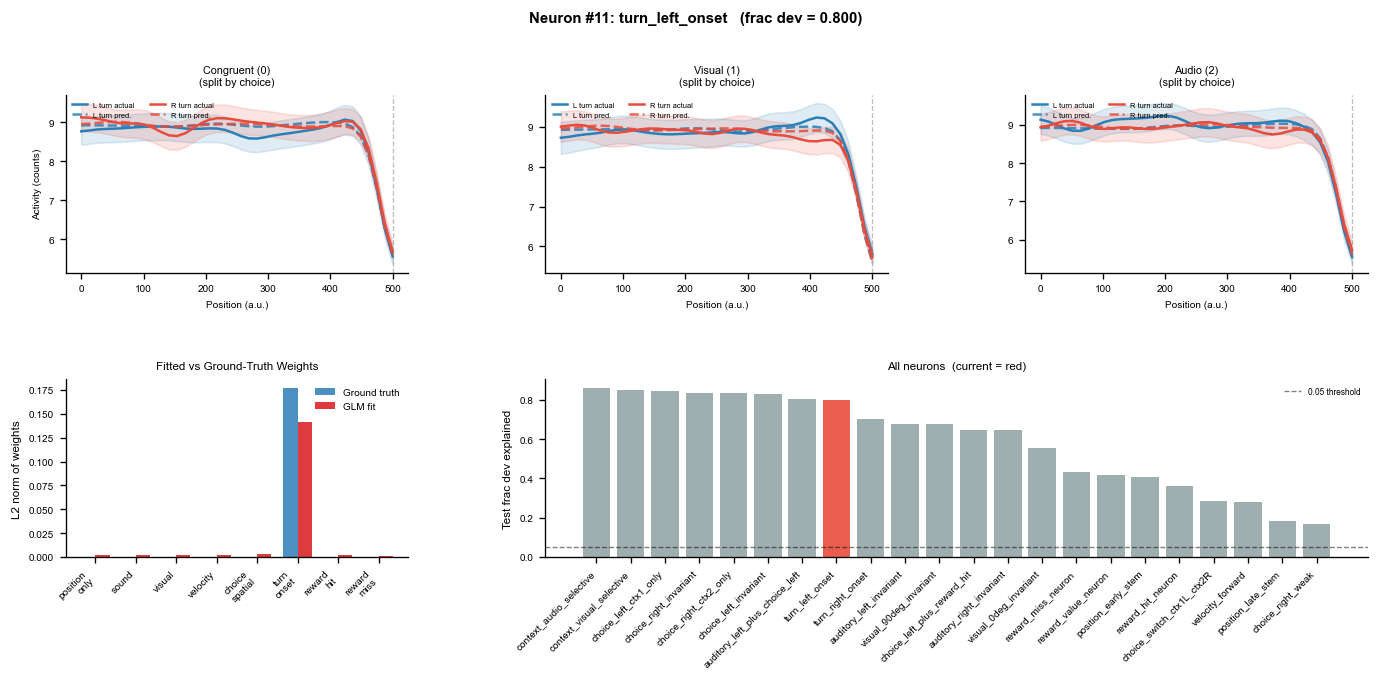

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


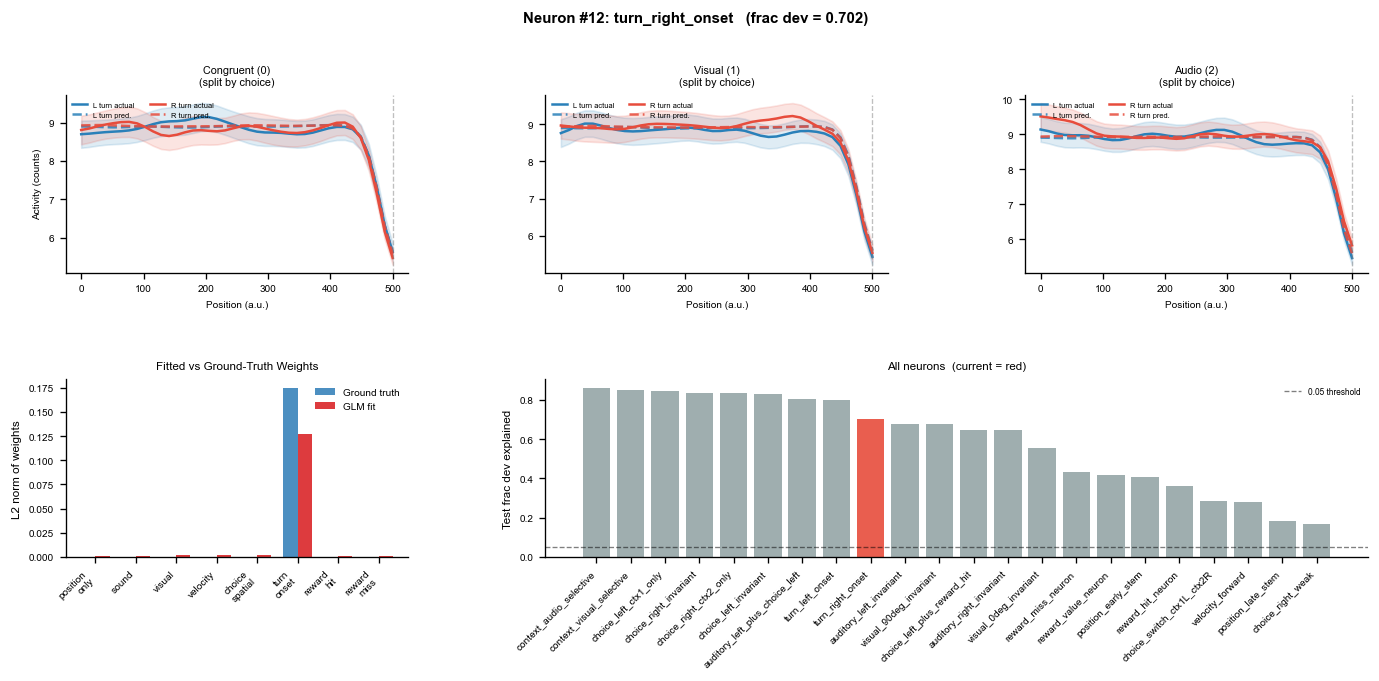

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


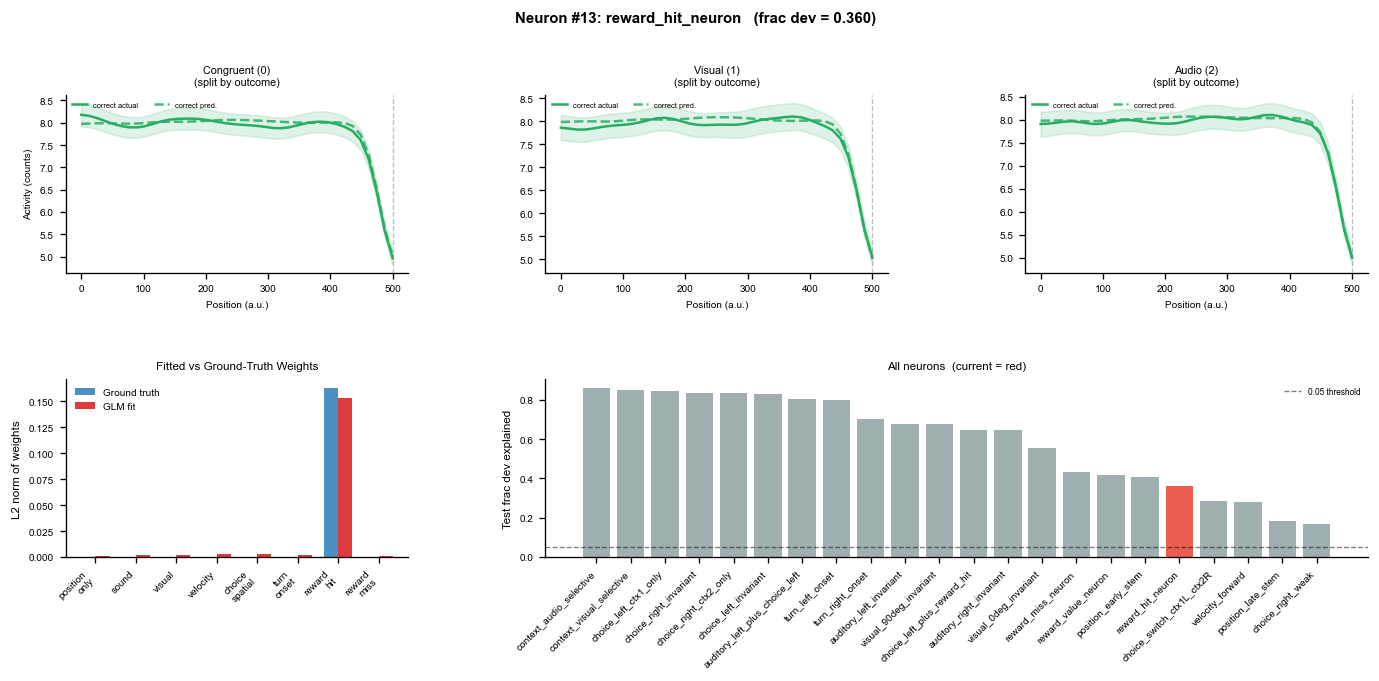

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


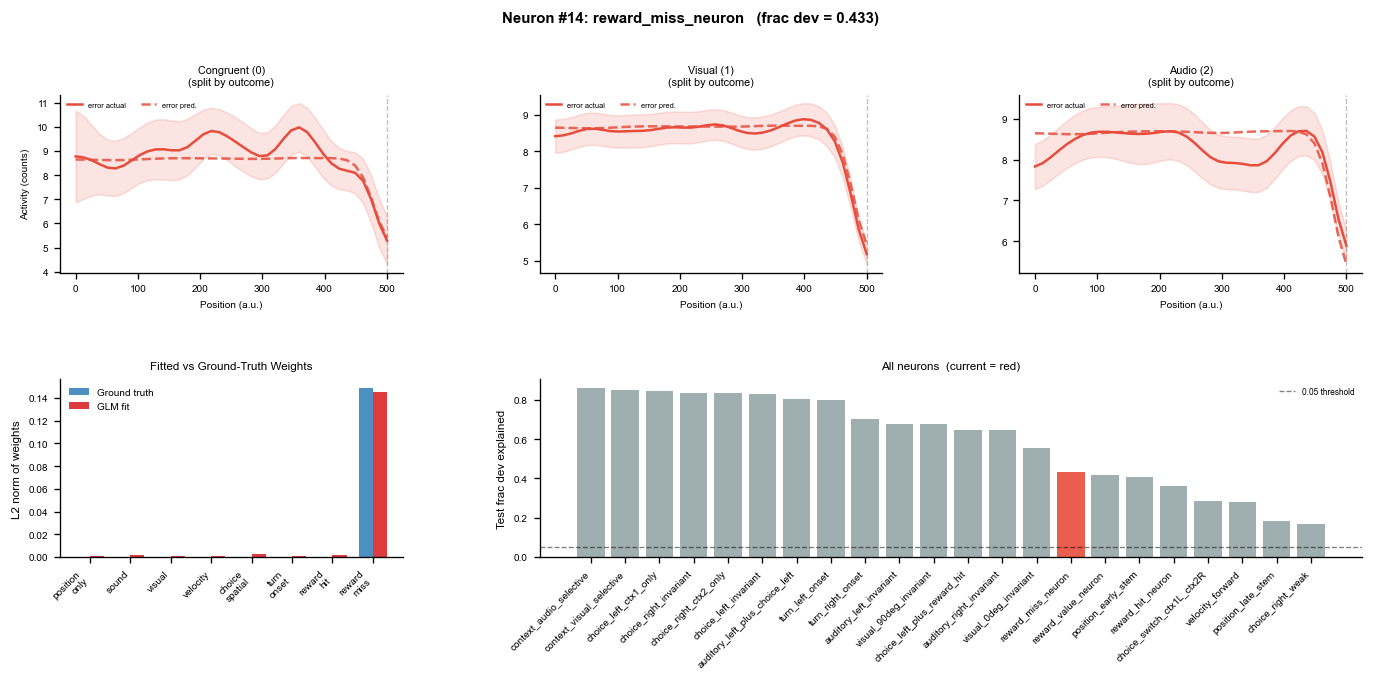

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


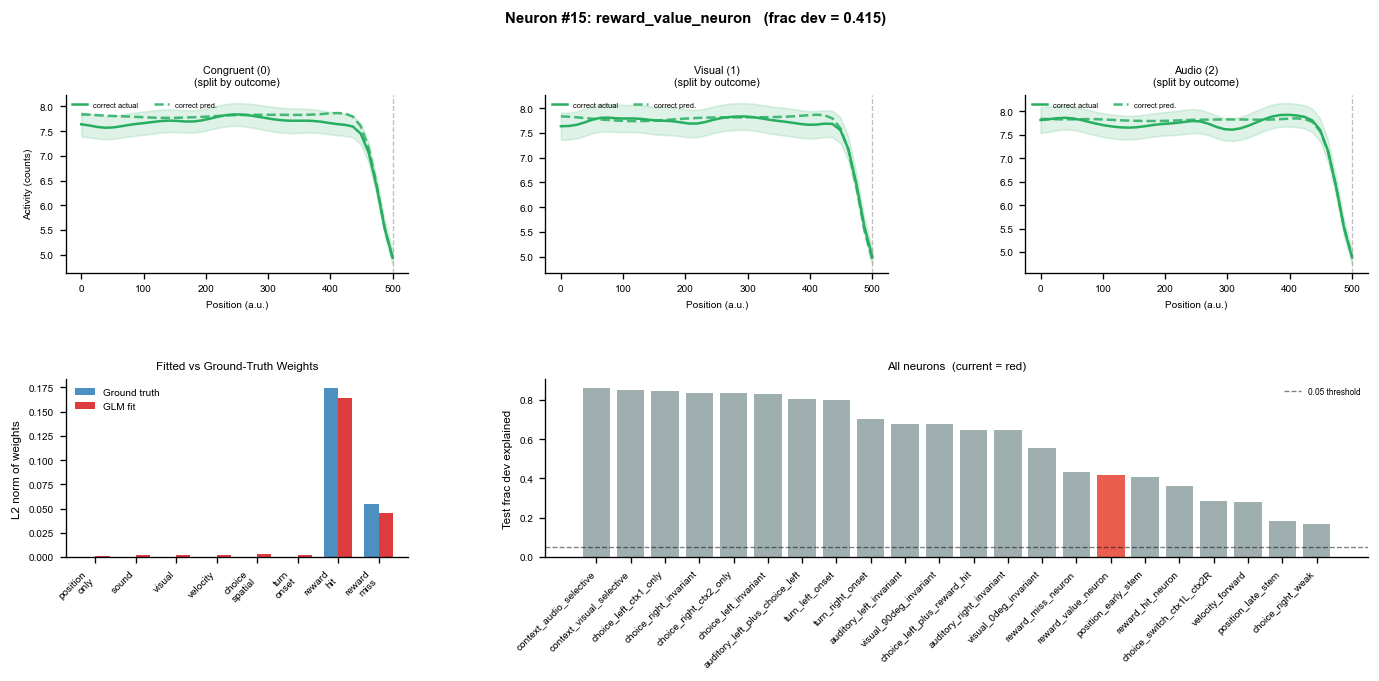

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


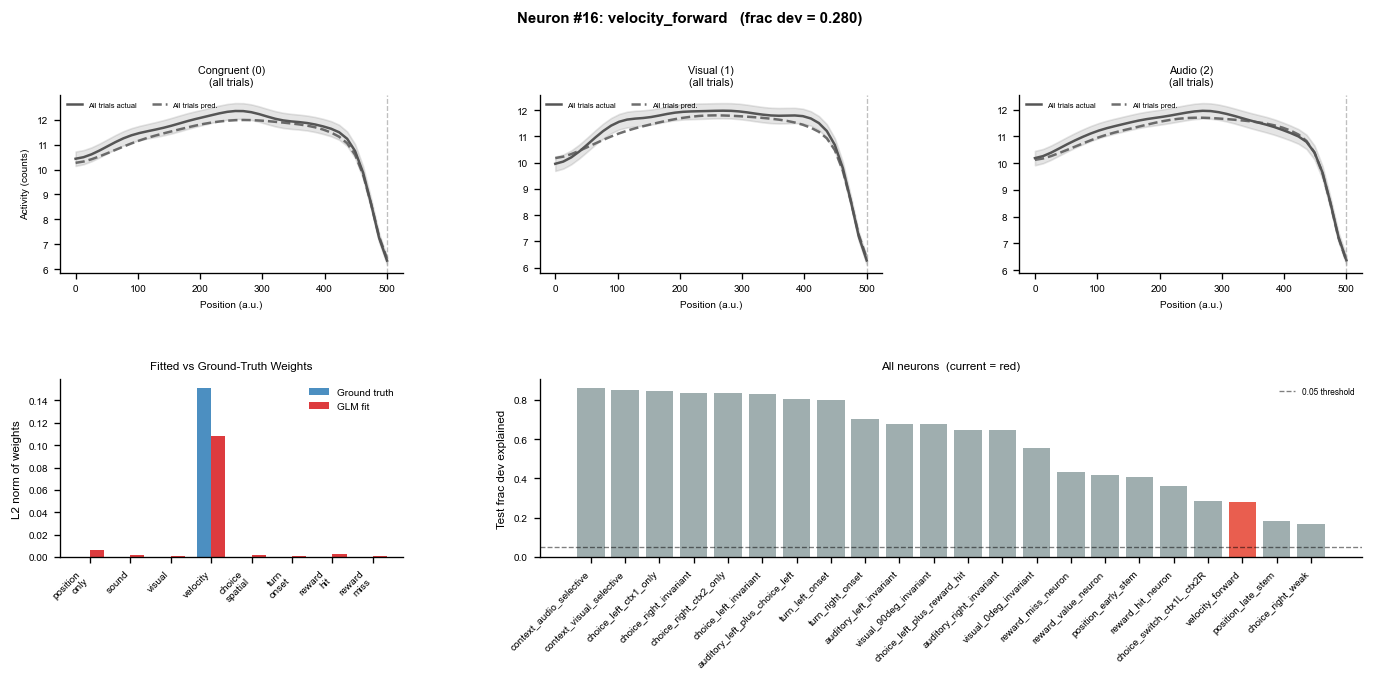

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


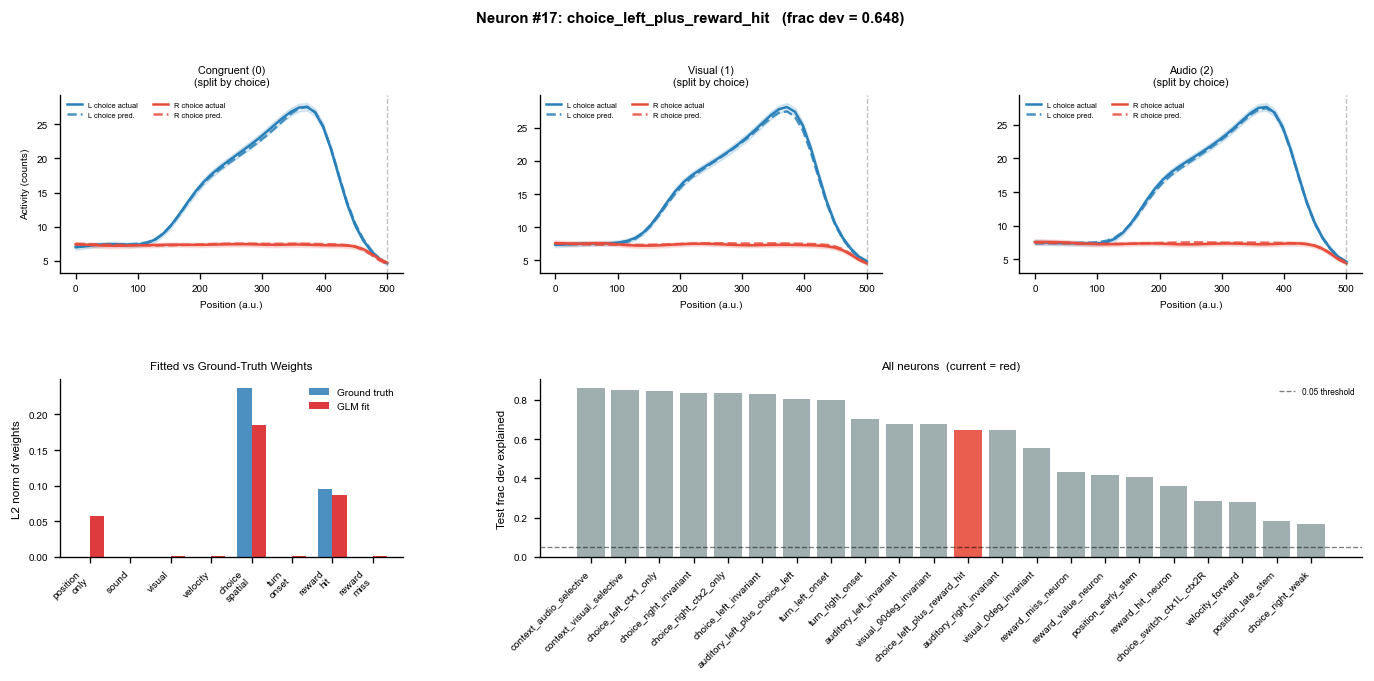

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


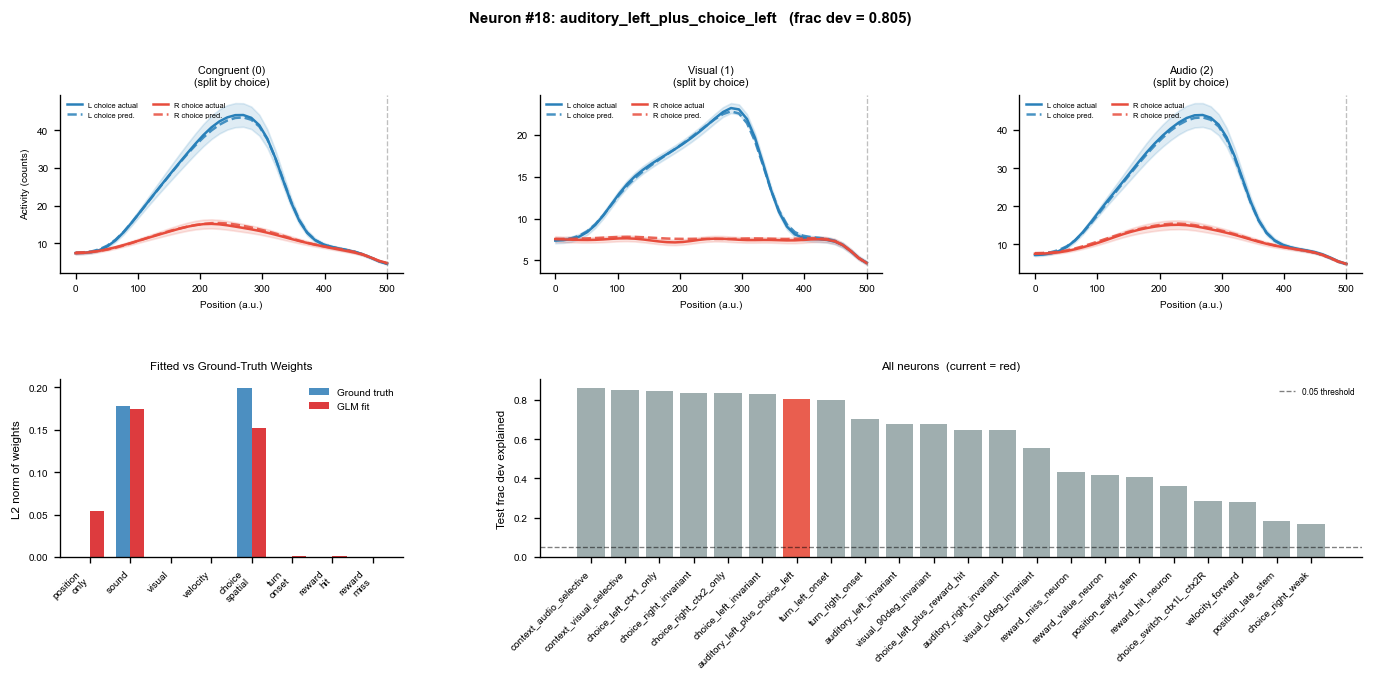

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


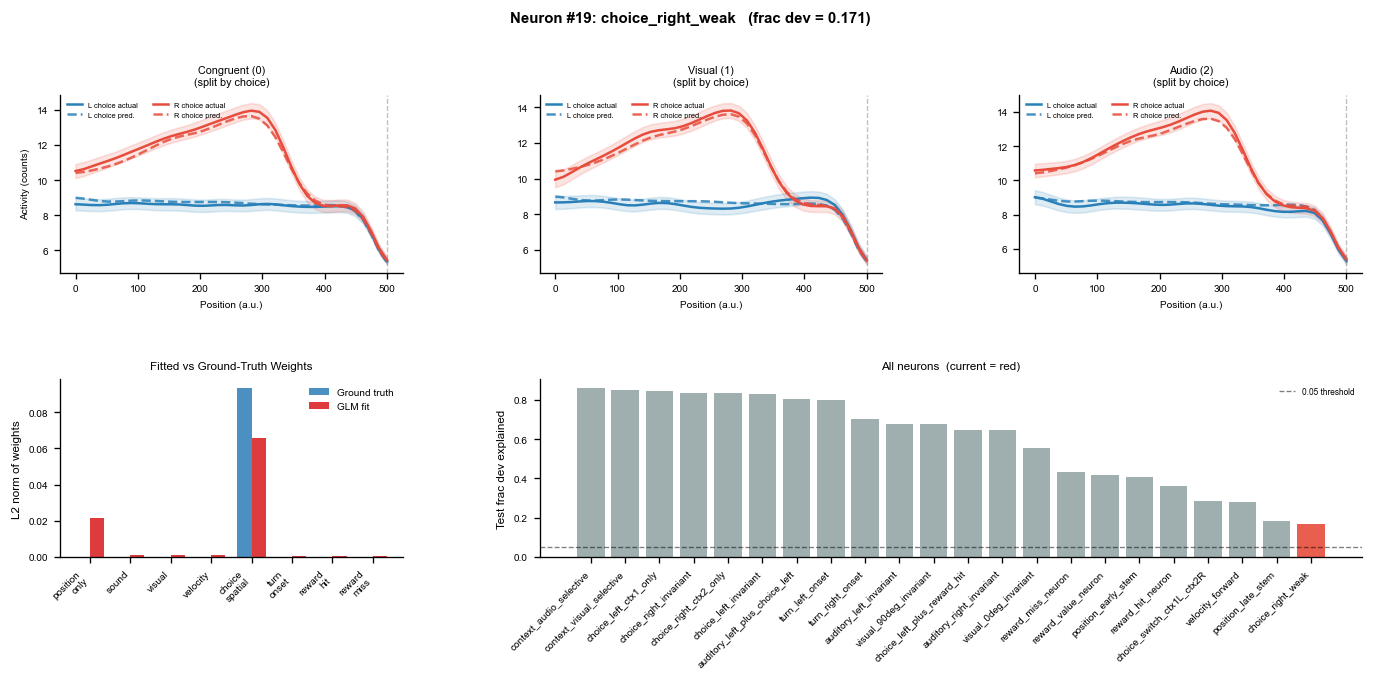

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


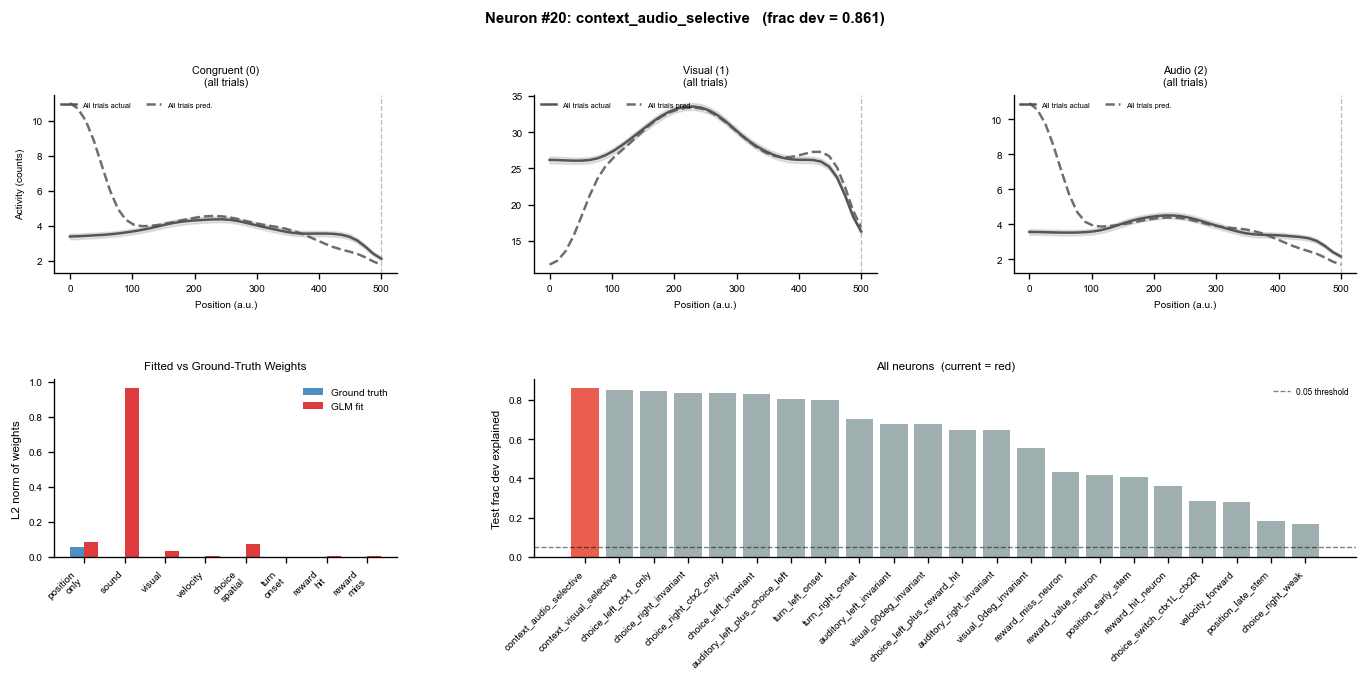

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_6151/2182552967.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


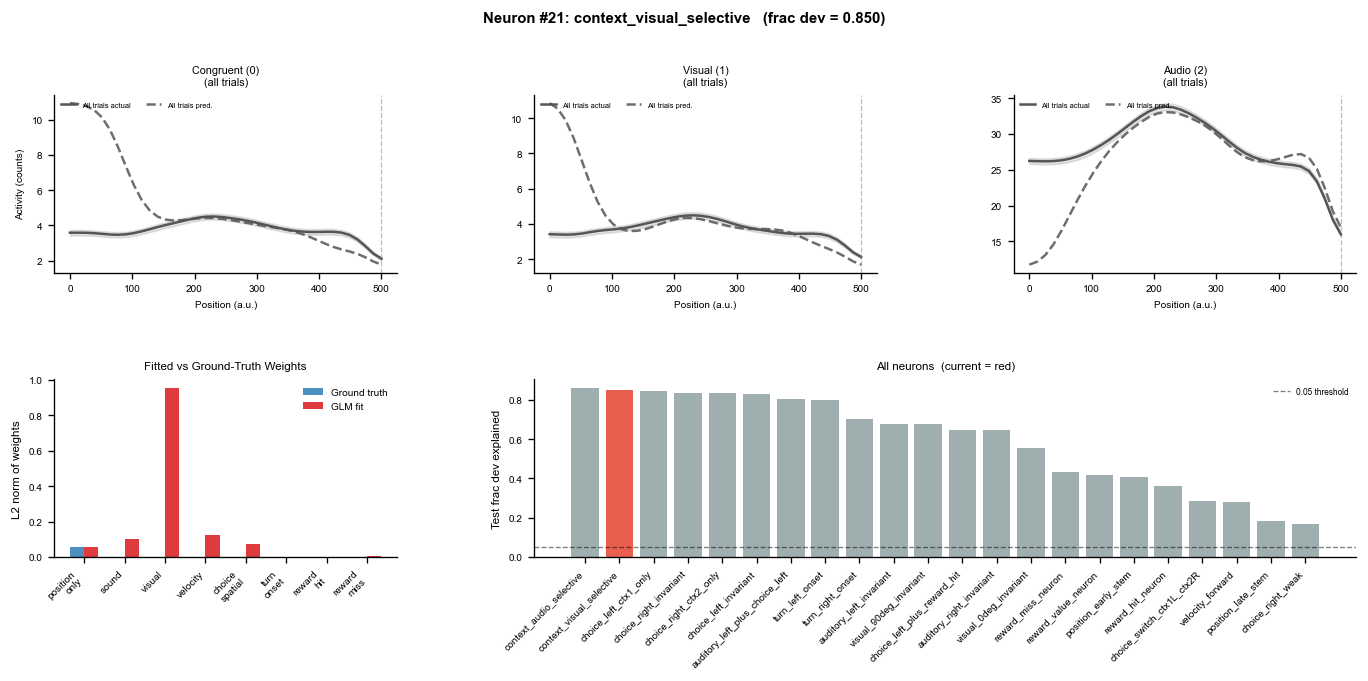

✓ Done


In [12]:
import scipy.stats
from scipy.ndimage import gaussian_filter1d
from scipy.interpolate import interp1d

# ── Split-condition config per predictor group ────────────────────────────────
# Each entry defines how to split trials for the top-row PSTH.
# key      : field in synthetic_glm_dict[ti] to read the condition from
# v1 / v2  : the two values to compare
# l1 / l2  : legend labels for the two conditions
# c1 / c2  : line colours
# None     : no split — all trials averaged into one trace
SPLIT_CONFIG = {
    'choice_spatial': dict(key='choice',      v1=0,     v2=1,
                           l1='L choice', l2='R choice',
                           c1='#2980b9',  c2='#e74c3c'),
    'turn_onset':     dict(key='choice',      v1=0,     v2=1,
                           l1='L turn',   l2='R turn',
                           c1='#2980b9',  c2='#e74c3c'),
    'sound':          dict(key='Audio_Stim',  v1=-90.0, v2=90.0,
                           l1='L audio',  l2='R audio',
                           c1='#2980b9',  c2='#e74c3c'),
    'visual':         dict(key='Visual_Stim', v1=0.0,   v2=90.0,
                           l1='0° visual', l2='90° visual',
                           c1='#27ae60',  c2='#8e44ad'),
    'reward_hit':     dict(key='outcome',     v1=1,     v2=None,
                           l1='correct',  l2=None,
                           c1='#27ae60',  c2=None),
    'reward_miss':    dict(key='outcome',     v1=0,     v2=None,
                           l1='error',    l2=None,
                           c1='#e74c3c',  c2=None),
    'position_only':  None,
    'velocity':       None,
}

# Priority order used when a neuron encodes multiple groups (mixed selectivity)
SPLIT_PRIORITY = [
    'choice_spatial', 'turn_onset', 'sound', 'visual',
    'reward_hit', 'reward_miss', 'position_only', 'velocity', 'reward',
]


def _get_split_config(neuron_idx, ground_truth):
    """Return the SPLIT_CONFIG entry appropriate for this neuron."""
    groups = ground_truth['neuron_types'][neuron_idx]['groups']
    for grp in SPLIT_PRIORITY:
        if grp in groups:
            return SPLIT_CONFIG.get(grp)
    return None   # fallback: no split


def plot_simulated_neuron_analysis(
    neuron_idx,
    synthetic_glm_dict,
    model_cv,
    ground_truth,
    test_frac_dev,
    predictor_info,
    X, Y,
    metadata,
    train_mask, test_mask,
    Y_test_pred,
    sampling_rate=15.6,
    smooth_sigma=2,
    n_pos_bins=40,
):
    """
    Comprehensive validation figure for one simulated neuron.

    Layout (2 rows × 3 cols):
      Top row:    Position-aligned actual (solid) + predicted (dashed), split by the
                  condition appropriate for this neuron type, one subplot per context.
      Bottom row: [Fitted vs ground-truth weights (col 0)] | [All-neuron frac_dev (cols 1-2)]
    """
    neuron_name = ground_truth.get('neuron_names', [f'neuron_{neuron_idx}'])[neuron_idx]
    n_neurons   = Y.shape[1]
    split_cfg   = _get_split_config(neuron_idx, ground_truth)

    # ── Pre-compute full-array predictions ───────────────────────────────────
    Y_train_pred_full = make_prediction(
        X[train_mask], model_cv.selected_w,
        model_cv.selected_w0.flatten(), activation=model_cv.activation
    )
    Y_full_pred = np.zeros(Y.shape[0])
    Y_full_pred[train_mask] = Y_train_pred_full[:, neuron_idx]
    Y_full_pred[test_mask]  = Y_test_pred[:, neuron_idx]

    # ── Figure layout ────────────────────────────────────────────────────────
    fig = plt.figure(figsize=(14, 5), dpi=120)
    gs  = fig.add_gridspec(2, 3, hspace=0.6, wspace=0.4)

    ax_ctx = [fig.add_subplot(gs[0, i]) for i in range(3)]
    ax_w   = fig.add_subplot(gs[1, 0])
    ax_bar = fig.add_subplot(gs[1, 1:])   # spans cols 1–2

    ctx_labels    = ['Congruent (0)', 'Visual (1)', 'Audio (2)']
    position_bins = np.linspace(0, 500, n_pos_bins)

    # Determine subplot title suffix showing the split variable
    if split_cfg is None:
        split_subtitle = 'all trials'
    else:
        split_subtitle = f"split by {split_cfg['key']}"

    # ── TOP ROW: actual (solid) + predicted (dashed) per context ─────────────
    for ctx_idx, ctx_label in enumerate(ctx_labels):
        ax = ax_ctx[ctx_idx]

        # Buckets: cond1 / cond2 / unsplit (when split_cfg is None)
        actual_c1, actual_c2, actual_all = [], [], []
        pred_c1,   pred_c2,   pred_all   = [], [], []

        for ti, td in synthetic_glm_dict.items():
            if td['context'] != ctx_idx or td['neural'] is None:
                continue

            cf     = td['events']['choice_frame']
            y_pos  = np.asarray(td['movement']['y_position']).flatten()[:cf]
            a_stem = td['neural'][:cf, neuron_idx]

            trial_frames = np.where(metadata['trial_id'] == ti)[0]
            stem_global  = trial_frames[:cf]
            if len(stem_global) == 0 or len(y_pos) < 5:
                continue
            p_stem = Y_full_pred[stem_global]

            try:
                fa = interp1d(y_pos, a_stem, kind='linear',
                              bounds_error=False, fill_value=0)
                fp = interp1d(y_pos, p_stem, kind='linear',
                              bounds_error=False, fill_value=0)
                a_trace = fa(position_bins)
                p_trace = fp(position_bins)
            except Exception:
                continue

            if split_cfg is None:
                actual_all.append(a_trace)
                pred_all.append(p_trace)
            else:
                trial_val = td[split_cfg['key']]
                if trial_val == split_cfg['v1']:
                    actual_c1.append(a_trace); pred_c1.append(p_trace)
                elif split_cfg['v2'] is not None and trial_val == split_cfg['v2']:
                    actual_c2.append(a_trace); pred_c2.append(p_trace)

        # Build plot spec: list of (actual_list, pred_list, color, label)
        if split_cfg is None:
            plot_spec = [(actual_all, pred_all, '#555555', 'All trials')]
        elif split_cfg['v2'] is None:
            # Single-condition split (e.g. reward_hit: only correct trials shown)
            plot_spec = [
                (actual_c1, pred_c1, split_cfg['c1'], split_cfg['l1']),
            ]
        else:
            plot_spec = [
                (actual_c1, pred_c1, split_cfg['c1'], split_cfg['l1']),
                (actual_c2, pred_c2, split_cfg['c2'], split_cfg['l2']),
            ]

        for actual_tr, pred_tr, color, label in plot_spec:
            if len(actual_tr) > 0:
                am  = gaussian_filter1d(np.mean(actual_tr, axis=0), smooth_sigma)
                pm  = gaussian_filter1d(np.mean(pred_tr,   axis=0), smooth_sigma)
                sem = gaussian_filter1d(scipy.stats.sem(actual_tr,  axis=0), smooth_sigma)

                ax.plot(position_bins, am, color=color, lw=1.5,
                        label=f'{label} actual')
                ax.fill_between(position_bins, am - sem, am + sem,
                                color=color, alpha=0.15)
                ax.plot(position_bins, pm, color=color, lw=1.5,
                        ls='--', alpha=0.85, label=f'{label} pred.')

        ax.axvline(500, color='gray', ls='--', lw=0.8, alpha=0.5)
        ax.set_title(f'{ctx_label}\n({split_subtitle})', fontsize=6.5)
        ax.set_xlabel('Position (a.u.)', fontsize=6)
        if ctx_idx == 0:
            ax.set_ylabel('Activity (counts)', fontsize=6)
        ax.legend(fontsize=4.5, frameon=False, loc='upper left', ncol=2)
        ax.tick_params(labelsize=6)

    # ── BOTTOM LEFT: Fitted vs ground-truth weights (L2 per predictor group) ──
    fitted_w = model_cv.selected_w[:, neuron_idx]
    true_w   = ground_truth.get('w_true', np.zeros((X.shape[1], n_neurons)))[:, neuron_idx]

    grp_names, l2_true, l2_fitted = [], [], []
    for gname, info in predictor_info.items():
        s, e = info['start'], info['end']
        grp_names.append(gname.replace('_', '\n'))
        l2_true.append(np.linalg.norm(true_w[s:e]))
        l2_fitted.append(np.linalg.norm(fitted_w[s:e]))

    x_pos = np.arange(len(grp_names))
    bar_w = 0.35
    ax_w.bar(x_pos - bar_w / 2, l2_true,   bar_w, label='Ground truth',
             color='#2c7bb6', alpha=0.85)
    ax_w.bar(x_pos + bar_w / 2, l2_fitted, bar_w, label='GLM fit',
             color='#d7191c', alpha=0.85)
    ax_w.set_xticks(x_pos)
    ax_w.set_xticklabels(grp_names, rotation=45, ha='right', fontsize=5.5)
    ax_w.set_ylabel('L2 norm of weights', fontsize=7)
    ax_w.set_title('Fitted vs Ground-Truth Weights', fontsize=7)
    ax_w.legend(fontsize=6, frameon=False)
    ax_w.tick_params(labelsize=6)

    # ── BOTTOM RIGHT: All-neuron frac-dev ranked bar ──────────────────────────
    sorted_idx    = np.argsort(test_frac_dev)[::-1]
    bar_colors    = ['#e74c3c' if i == neuron_idx else '#95a5a6' for i in sorted_idx]
    neuron_labels = [ground_truth['neuron_names'][i] for i in sorted_idx]

    ax_bar.bar(np.arange(n_neurons), test_frac_dev[sorted_idx],
               color=bar_colors, alpha=0.9)
    ax_bar.axhline(0.05, color='k', ls='--', lw=0.8, alpha=0.5,
                   label='0.05 threshold')
    ax_bar.set_xticks(np.arange(n_neurons))
    ax_bar.set_xticklabels(neuron_labels, rotation=45, ha='right', fontsize=5)
    ax_bar.set_ylabel('Test frac dev explained', fontsize=7)
    ax_bar.set_title('All neurons  (current = red)', fontsize=7)
    ax_bar.tick_params(labelsize=6)
    ax_bar.legend(fontsize=5, frameon=False)

    fig.suptitle(
        f'Neuron #{neuron_idx}: {neuron_name}   '
        f'(frac dev = {test_frac_dev[neuron_idx]:.3f})',
        fontsize=9, fontweight='bold', y=1.02
    )
    return fig


# ── Run for all 19 simulated neurons ─────────────────────────────────────────
print(f"Plotting {Y.shape[1]} simulated neurons...\n")

for ni in range(Y.shape[1]):
    fig = plot_simulated_neuron_analysis(
        neuron_idx         = ni,
        synthetic_glm_dict = synthetic_glm_dict,
        model_cv           = model_cv,
        ground_truth       = ground_truth,
        test_frac_dev      = test_frac_dev,
        predictor_info     = predictor_info,
        X                  = X,
        Y                  = Y,
        metadata           = metadata,
        train_mask         = train_mask,
        test_mask          = test_mask,
        Y_test_pred        = Y_test_pred,
        sampling_rate      = 15.6,
        smooth_sigma       = 2,
    )
    plt.tight_layout()
    plt.show()
    plt.close(fig)

print("✓ Done")